# 🚀 VLA 연구 · 5회차 실습
## CNN & 전이학습 — ResNet-18 · CIFAR-10 · k-fold

| 항목 | 내용 |
|------|------|
| 오늘 목표 | CNN 원리 이해, ResNet-18 전이학습, k-fold 교차 검증 직접 구현 |
| 미니과제 | freeze 실험표 + 틀린 예측 5개 분석 |
| 제출 방법 | 완성된 노트북을 공용 드라이브 공유 폴더에 저장 후 조교에게 링크 공유 |

> **이 노트북을 여는 순서**  
> 런타임 → 런타임 유형 변경 → **GPU (T4)** 선택 후 저장


>시각화 시 사용할 한글 폰트 설정 (아래 블록 실행 후 **런타임 재시작**)

In [ ]:
# 한글 폰트 설정 (Colab 환경)
import matplotlib
import matplotlib.font_manager as fm

## Colab에 나눔폰트 설치
import subprocess
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], capture_output=True)
fm._load_fontmanager(try_read_cache=False)  # 폰트 캐시 갱신

## 나눔고딕 적용
matplotlib.rcParams['font.family'] = 'NanumGothic'
matplotlib.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지


---
## SECTION 0  |  환경 확인

### 0-1. GPU 및 PyTorch 환경 확인

아래 셀을 실행하여 GPU와 PyTorch 버전을 확인하세요.  
**'No GPU'가 뜨면 런타임 → 런타임 유형 변경 → GPU로 설정하세요.**

In [ ]:
import torch
import sys

print('=== 환경 정보 ===')
print(f'Python  : {sys.version.split()[0]}')
print(f'PyTorch : {torch.__version__}')

if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'CUDA    : {torch.version.cuda}')
    device = torch.device('cuda')
    print('\n✓ GPU 사용 준비 완료')
else:
    print('⚠ GPU 없음 — 런타임 유형을 GPU로 변경하세요')
    device = torch.device('cpu')

print(f'\n사용 디바이스: {device}')


---
## SECTION 1  |  Google Drive 마운트 & 공용 드라이브 연결

### 1-1. 개인 Drive 마운트

개인 Drive를 마운트합니다. 노트북 작업 파일의 임시 저장·백업용으로 활용합니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/VLA_2026'
os.makedirs(DRIVE_BASE, exist_ok=True)
print(f'Drive 마운트 완료: {DRIVE_BASE}')


### 1-2. 공유 폴더 마운트

팀 공유 파일은 공유 폴더를 사용하여 관리합니다.  
**처음 실행 시**:

* 제공된 공유 폴더 링크에 접속합니다. (https://drive.google.com/drive/folders/1sP0yHhKYPg2tGAe3GXdMIGWjvWoj3FyV)

* 상단의 폴더 이름 옆 화살표를 누르거나 폴더를 우클릭하여 '드라이브에 바로가기 추가'를 클릭합니다.

* '내 드라이브'를 선택하고 바로가기를 생성합니다.

> **4회차와 동일**: 구글 드라이브 공유 폴더를 그대로 사용합니다.


In [ ]:
# 1. 공유 폴더 설정
# '내 드라이브'에 추가한 바로가기 폴더의 이름을 입력하세요.
FOLDER_NAME = 'VLA_Team_2026'
SHARED_DRIVE_PATH = f'/content/drive/MyDrive/{FOLDER_NAME}'

# 2. 팀 공유 폴더 구조 정의
TEAM_PATHS = {
    'notebooks'    : f'{SHARED_DRIVE_PATH}/notebooks/',
    'results'      : f'{SHARED_DRIVE_PATH}/results/',
    'models'       : f'{SHARED_DRIVE_PATH}/models/',
    'data'         : f'{SHARED_DRIVE_PATH}/data/',
}

# 3. 경로 유효성 확인
print(f"설정된 경로: {SHARED_DRIVE_PATH}\n")

if os.path.exists(SHARED_DRIVE_PATH):
    for name, path in TEAM_PATHS.items():
        if os.path.exists(path):
            print(f'✓ {name:12s}: 연결 완료')
        else:
            print(f'⚠ {name:12s}: 폴더 미생성 — {path}')
else:
    print(f'❌ 오류: "{FOLDER_NAME}" 폴더를 찾을 수 없습니다.')
    print('   -> 구글 드라이브에서 "드라이브에 바로가기 추가"를 완료했는지 확인하세요.')


### 1-3. 파일 저장 편의 함수

매번 경로를 타이핑하는 대신 Python 함수로 편하게 사용합니다.  
이후 회차에서도 이 함수들을 재사용합니다.

In [ ]:
import shutil
import os
from datetime import datetime

def team_save(local_path: str, folder: str = 'notebooks'):
    """로컬 파일을 공유 폴더 내 지정된 디렉토리로 복사"""
    if 'TEAM_PATHS' not in globals():
        print("❌ 오류: TEAM_PATHS가 정의되지 않았습니다. 마운트 블록을 먼저 실행하십시오.")
        return None

    target_dir = TEAM_PATHS.get(folder)
    if not target_dir:
        print(f"❌ 오류: 유효하지 않은 폴더 키입니다. (선택 가능: {list(TEAM_PATHS.keys())})")
        return None

    os.makedirs(target_dir, exist_ok=True)
    filename = os.path.basename(local_path)
    target_path = os.path.join(target_dir, filename)

    try:
        shutil.copy2(local_path, target_path)
        print(f'✓ 공유 폴더 저장 완료: {target_path}')
        return target_path
    except PermissionError:
        print(f'❌ 권한 오류: 해당 공유 폴더에 쓰기 권한이 있는지 확인하십시오.')
    except Exception as e:
        print(f'❌ 저장 실패: {e}')
    return None

def team_load(filename: str, folder: str = 'data'):
    """공유 폴더 내 파일을 코랩 가상 머신의 /tmp 디렉토리로 복사 후 경로 반환"""
    if 'TEAM_PATHS' not in globals():
        print("❌ 오류: TEAM_PATHS가 정의되지 않았습니다.")
        return None

    src = os.path.join(TEAM_PATHS.get(folder, ''), filename)
    if not os.path.exists(src):
        print(f"❌ 파일 미발견: {src}\n   파일명과 폴더 위치를 다시 확인하십시오.")
        return None

    dst = os.path.join('/tmp', filename)
    try:
        shutil.copy2(src, dst)
        print(f'✓ 로컬 로드 완료: {dst}')
        return dst
    except Exception as e:
        print(f'❌ 로드 실패: {e}')
        return None

print('✓ 공유 폴더 편의 함수 등록 완료')


---
## SECTION 2  |  CNN 기초 — Convolution · Pooling · 특징맵

### 2-1. 왜 CNN인가?

> **4회차 복습**: MLP(다층 퍼셉트론)는 이미지를 1D로 펼쳐서 처리했습니다.  
> 28×28 이미지 → 784개 숫자. 이 방식은 픽셀 간의 **공간적 관계**(위아래, 좌우)를 전혀 활용하지 못합니다.

CNN(합성곱 신경망)은 **필터**(kernel)를 슬라이딩하며 이미지의 지역적 패턴을 추출합니다.  
같은 필터를 이미지 전체에 반복 적용하므로 파라미터 수가 훨씬 적고, 위치가 달라져도 패턴을 인식할 수 있습니다.

> **VLA 파이프라인 연결**: VLM과 smolVLA 모두 이미지 인코더로 CNN 기반 모델(ViT, ResNet)을 사용합니다.  
> 오늘 배우는 내용이 7회차 CLIP 실습과 12회차 smolVLA 파인튜닝의 직접적 기반입니다.

### 2-2. Conv2d — 합성곱 레이어

| 파라미터 | 의미 | 예시 |
|----------|------|------|
| `in_channels` | 입력 채널 수 | RGB 이미지: 3 |
| `out_channels` | 출력 채널(필터) 수 | 32개 필터 → 32개 특징맵 |
| `kernel_size` | 필터 크기 | 3 = 3×3 필터 |
| `padding` | 입력 주변 0 패딩 | `padding=1`이면 출력 크기 유지 |

출력 크기 공식: $\lfloor \frac{H - K + 2P}{S} \rfloor + 1$  
(H=입력 크기, K=커널 크기, P=패딩, S=스트라이드)

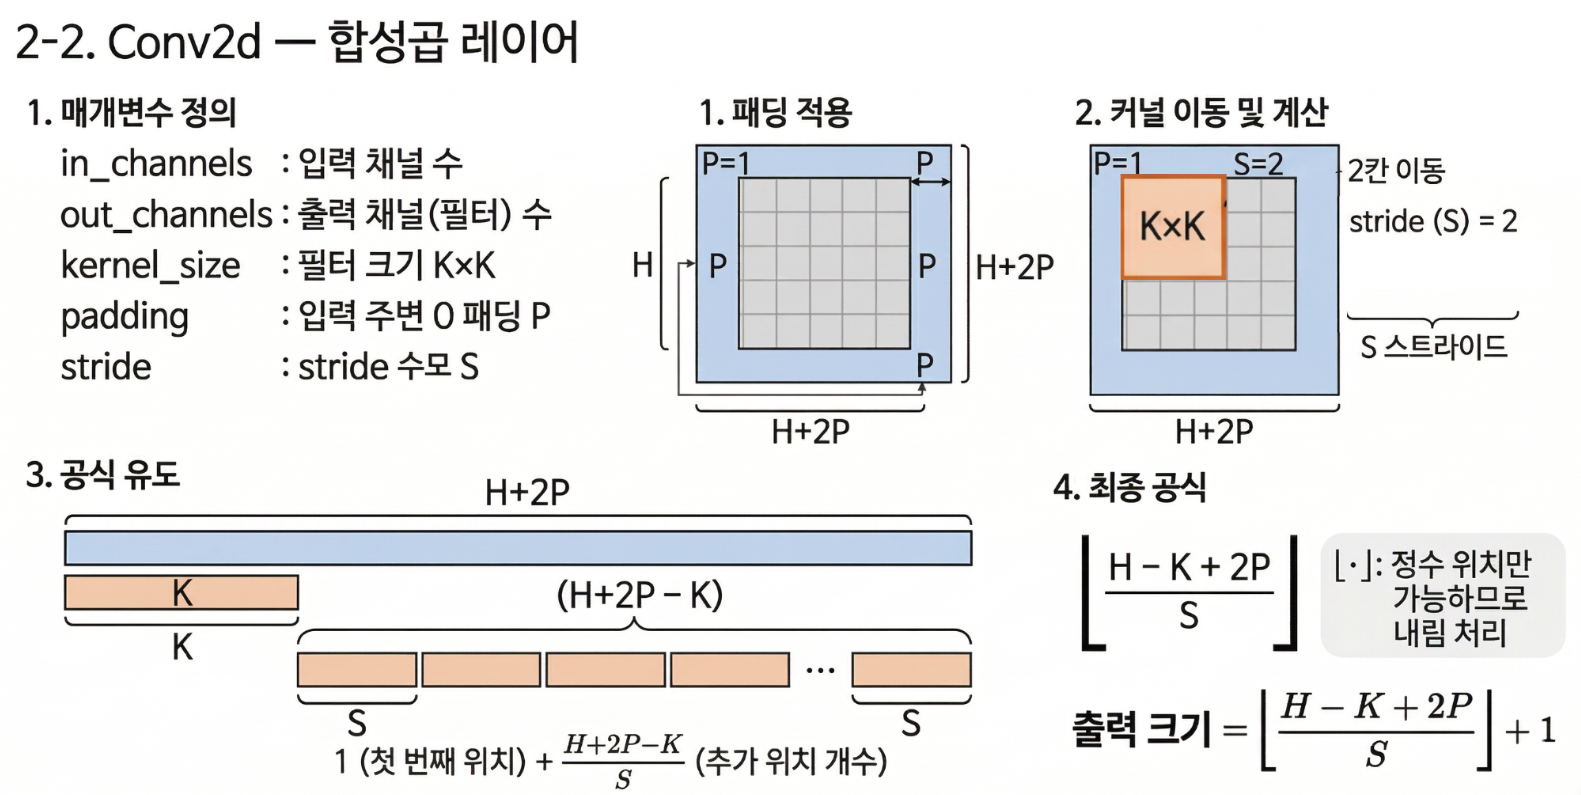

In [ ]:
import torch
import torch.nn as nn

# Conv2d 기본 사용법
conv = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)

# 입력: (batch=2, C=3, H=32, W=32)
x = torch.randn(2, 3, 32, 32)
out = conv(x)

print(f'입력  shape: {x.shape}    # (batch, in_channels, H, W)')
print(f'출력  shape: {out.shape}   # (batch, out_channels, H, W)')
print(f'필터  shape: {conv.weight.shape}  # (out_ch, in_ch, kH, kW)')
print(f'파라미터 수: {conv.weight.numel() + conv.bias.numel():,}  '
      f'(MLP 같은 크기라면 {3*32*32*32*32*32:,}개 필요)')


### 2-3. MaxPool2d & 특징맵 시각화

MaxPool은 특징맵을 공간적으로 축소하면서 가장 강한 신호만 남깁니다.  
이미지 크기를 줄여 연산량을 감소시키고, 위치 변화에 강인해집니다.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms

# 1. 테스트 이미지 (MNIST 숫자 활용)
transform = transforms.Compose([transforms.ToTensor()])
sample_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_img = sample_data[24][0].unsqueeze(0) # 숫자 샘플

# 2. 모델 레이어
conv_layer = nn.Conv2d(1, 8, kernel_size=3, padding=1)
relu_layer = nn.ReLU()
pool_layer = nn.MaxPool2d(kernel_size=2, stride=2)

with torch.no_grad():
    nn.init.kaiming_normal_(conv_layer.weight) #가중치 초기화

    out_conv = conv_layer(test_img)
    out_relu = relu_layer(out_conv)
    out_pool = pool_layer(out_relu)

# 3. 시각화
# 원본 / ReLU 후(특징 추출) / MaxPool 후(압축) 비교
fig, axes = plt.subplots(3, 9, figsize=(18, 7))

# 첫 번째 열: 원본 이미지
axes[0, 0].imshow(test_img[0, 0].numpy(), cmap='gray')
axes[0, 0].set_title('Original Input', fontsize=10)
for i in range(3): axes[i, 0].axis('off')

# 나머지 열: 8개 필터의 변화 과정
for i in range(8):
    # Conv + ReLU 결과 (특징 추출 강조)
    axes[0, i+1].imshow(out_relu[0, i].numpy(), cmap='magma')
    axes[0, i+1].set_title(f'Feature {i+1}', fontsize=9)

    # MaxPool 결과 (해상도 감소 및 강한 신호 유지)
    axes[1, i+1].imshow(out_pool[0, i].numpy(), cmap='magma')
    axes[1, i+1].set_title(f'Pooled {i+1}', fontsize=9)

    # 히스토그램 (선택사항: 신호가 어떻게 살아남는지 수치적으로 확인)
    axes[2, i+1].hist(out_relu[0, i].numpy().flatten(), bins=10, color='gray', alpha=0.7)
    axes[2, i+1].set_yticks([])

# 라벨링 및 정리
axes[0, 0].set_ylabel('ReLU Output', rotation=0, labelpad=40, size=12)
axes[1, 0].set_ylabel('MaxPool Output', rotation=0, labelpad=40, size=12)
axes[2, 0].set_ylabel('Signal Dist.', rotation=0, labelpad=40, size=12)

plt.suptitle('CNN Feature Extraction & Spatial Pooling Process', fontsize=15)
plt.tight_layout()
plt.show()

print(f"Original shape: {test_img.shape}")
print(f"After MaxPool shape: {out_pool.shape} (Strongest signals preserved)")

---
## SECTION 3  |  BatchNorm & Dropout — 학습 안정화

### 3-1. BatchNorm2d — 배치 정규화

> **4회차 복습**: `BatchNorm1d`는 1D 데이터(MLP)에 사용했습니다.  
> CNN에서는 `BatchNorm2d`를 사용합니다. 채널 단위로 평균·분산을 정규화합니다.

**왜 필요한가?** 레이어가 깊어질수록 각 레이어의 입력 분포가 계속 달라집니다(Internal Covariate Shift).  
BatchNorm은 각 미니배치 단위로 입력을 정규화하여 학습을 빠르고 안정적으로 만듭니다.

```
# 일반적인 CNN 블록 순서 (B,A,D 패턴)
Conv → BatchNorm → ReLU → Pooling   # ✅ 정규화 후 활성화
Conv → ReLU → BatchNorm → Pooling   # ❌

```

In [ ]:
import torch
import torch.nn as nn

# BatchNorm2d: 채널 단위로 정규화
bn = nn.BatchNorm2d(num_features=32)  # 32채널 특징맵에 적용

x = torch.randn(8, 32, 14, 14)   # (batch=8, C=32, H=14, W=14)
out_bn = bn(x)

print('정규화 전 통계 (채널 0):')
print(f'  평균: {x[:, 0].mean():.4f}  표준편차: {x[:, 0].std():.4f}')
print('정규화 후 통계 (채널 0):')
print(f'  평균: {out_bn[:, 0].mean():.4f}  표준편차: {out_bn[:, 0].std():.4f}')

# 학습/평가 모드 차이
print('\n▶ train 모드: 현재 배치 통계 사용')
print('▶ eval  모드: 학습 중 누적한 이동 평균 통계 사용')
print('\n→ model.eval() 없이 평가하면 배치마다 다른 결과가 나올 수 있습니다!')


### 3-2. Dropout — 과적합 방지

학습 중 랜덤하게 뉴런을 꺼서 특정 뉴런에 과도하게 의존하지 않도록 합니다.  
**eval 모드에서는 자동으로 비활성화**됩니다 (`model.eval()` 호출 시).

In [ ]:
import torch
import torch.nn as nn

dropout = nn.Dropout(p=0.5)

x = torch.ones(1, 10)

dropout.train()   # 학습 모드
out_train = dropout(x)
print(f'학습 모드 (일부 뉴런이 0으로):')
print(out_train)

dropout.eval()    # 평가 모드
out_eval = dropout(x)
print(f'\n평가 모드 (모든 뉴런 활성):')
print(out_eval)

# Dropout2d: CNN의 채널 단위 드롭아웃 (채널 전체를 0으로)
dropout2d = nn.Dropout2d(p=0.3)
feat = torch.randn(2, 8, 14, 14)
dropout2d.train() # <--- FIXED: Call train() on the module, not the tensor
out_2d = dropout2d(feat)
print(f'\nDropout2d: 8채널 중 {(out_2d[0].abs().sum(dim=(1,2)) == 0).sum().item()}개 채널이 소거됨')

### 3-3. 연습문제 ✏️

아래 문제를 풀어보세요.
* 우선 스스로 작성해 보세요.
* 막힌다면 충분히 고민한 이후에 Claude Code에 질문하세요.

In [ ]:
# 문제 1
# in_channels=1, out_channels=16, kernel_size=5, padding=2 인 Conv2d를 만들고
# (1, 1, 28, 28) 크기의 입력을 통과시켰을 때 출력 shape을 출력하세요.
# 공식을 이용해 손으로 먼저 계산하고, 코드로 검증해 보세요.

# 여기에 코드 작성


In [ ]:
# 문제 2
# 아래 CNN 블록의 총 파라미터 수를 직접 계산하고 sum()으로 검증하세요.
# Conv2d(3, 64, 3, padding=1) → BatchNorm2d(64) → Conv2d(64, 128, 3, padding=1)
# 힌트: Conv 파라미터 = out_ch × in_ch × kH × kW + out_ch (=bias)
#       BatchNorm 파라미터 = 2 (=스케일 조절용 가중치, 이동 조절용 편향) × num_features

# 여기에 코드 작성


In [ ]:
# 문제 3
# (1, 3, 64, 64) 배치 이미지를 아래 순서로 통과시키고 각 단계의 shape을 출력하세요.
# Conv2d(3, 32, 3, padding=1) → MaxPool2d(2, 2) → Conv2d(32, 64, 3, padding=1) → MaxPool2d(2, 2)
# 마지막으로 Flatten 후 shape을 확인하세요.

# 여기에 코드 작성




---
## SECTION 4  |  전이학습 — Transfer Learning

### 4-1. 전이학습이란?

ImageNet(120만 장, 1,000 클래스)으로 사전학습된 모델의 **가중치를 그대로 가져와**  
우리 문제에 맞게 일부만 다시 학습하는 방법입니다.

| 전략 | 방법 | 언제 사용? |
|------|------|------------|
| Feature Extractor | 전체 freeze, 마지막 FC만 학습 | 데이터 적을 때, 빠른 실험 |
| Fine-tuning | 일부 또는 전체 unfreeze | 데이터 충분, 더 높은 성능 필요 |

> **왜 전이학습이 강력한가?**  
> 사전학습 모델의 앞단 레이어는 에지, 텍스처 같은 **범용적 특징**을 이미 학습했습니다.  
> 우리가 새로 학습해야 하는 것은 이 특징들을 우리 클래스에 맞게 **조합하는 방법**뿐입니다.

> **VLA 파이프라인 연결**: smolVLA의 이미지 인코더도 사전학습된 ViT를 freeze하고  
> 행동 예측 헤드만 파인튜닝하는 구조를 씁니다.

### 4-2. ResNet-18 구조

ResNet(Residual Network)은 **잔차 연결(skip connection)** 로 깊은 네트워크의 기울기 소실 문제를 해결했습니다.  
ResNet-18: 18개 레이어, ImageNet Top-5 정확도 89.1%.

```
입력 이미지 (3, 224, 224)
    ↓ Conv1 (64, 112, 112)
    ↓ Layer1-4: Residual Blocks (점점 채널 ↑, 해상도 ↓)
    ↓ AvgPool (512, 1, 1)
    ↓ FC (1000) ← 이 레이어만 우리 클래스 수로 교체!
```

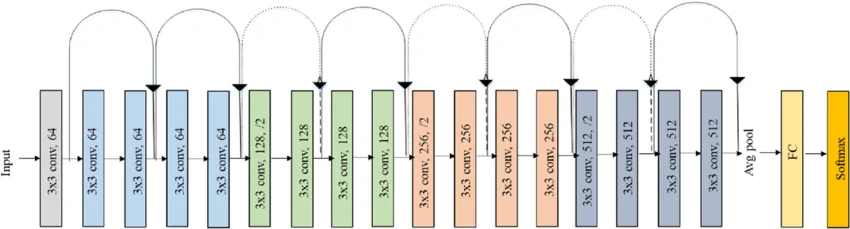

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

# 1. 모델 준비 및 FC 레이어 수정
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = nn.Linear(512, 10) # 1000개 클래스를 10개로 변경
resnet.eval() # 추론 모드로 설정

# 2. 가상의 입력 데이터 (Batch=1, RGB=3, 224x224)
x = torch.randn(1, 3, 224, 224)
print(f"입력 이미지 Shape: {x.shape}\n")

# 3. 주요 구간별 변환 과정 시각화
with torch.no_grad():
    # 초기 Conv & MaxPool (해상도 급격히 감소)
    x = resnet.conv1(x) #nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3)
    feature_maps = x ## 피처맵
    x = resnet.bn1(x)
    x = resnet.relu(x)
    x = resnet.maxpool(x)
    print(f"초기 특징 추출 (Conv1+MaxPool) 후: {x.shape}")

    # ResNet의 핵심 블록 (Layer 1~4)
    x = resnet.layer1(x)
    print(f"ResNet 블록 1 통과 후: {x.shape}")
    x = resnet.layer2(x)
    print(f"ResNet 블록 2 통과 후: {x.shape}")
    x = resnet.layer3(x)
    print(f"ResNet 블록 3 통과 후: {x.shape}")
    x = resnet.layer4(x)
    print(f"ResNet 블록 4 통과 후: {x.shape} (최종 특징 맵)")

    # Global Average Pooling
    x = resnet.avgpool(x)
    print(f"AvgPool(GAP) 통과 후: {x.shape} (공간 정보 요약)")

    # Flatten & FC
    x = torch.flatten(x, 1)
    print(f"Flatten 후: {x.shape}")
    x = resnet.fc(x)
    print(f"최종 FC 레이어 출력: {x.shape} (10개 클래스 확률)")


# 4. 시각화
fig, axes = plt.subplots(8, 8, figsize=(15, 15))
fig.suptitle('ResNet-18 Feature Maps', fontsize=20)

for i in range(64):
    row, col = divmod(i, 8)
    # 각 채널(피처 맵)을 하나씩 꺼내어 시각화
    f_map = feature_maps[0, i].numpy()

    axes[row, col].imshow(f_map, cmap='viridis')
    axes[row, col].axis('off')
    if i < 8: # 맨 윗줄만 타이틀 표시
        axes[row, col].set_title(f'Ch {i}')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

In [ ]:
import torch
import torchvision.models as models

# 사전학습된 ResNet-18 불러오기
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# 구조 확인
print('=== ResNet-18 마지막 레이어 ===')
print(f'FC 레이어: {resnet.fc}')  # Linear(512, 1000)

# 파라미터 수
total = sum(p.numel() for p in resnet.parameters())
print(f'\n전체 파라미터: {total:,}')

# freeze 실습: 모든 레이어를 얼림
for param in resnet.parameters():
    param.requires_grad = False

# FC만 교체하고 학습 가능하게 설정 (CIFAR-10: 10 클래스)
resnet.fc = torch.nn.Linear(512, 10)
# 새로 추가한 FC는 requires_grad=True (기본값)

trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
print(f'학습 가능 파라미터: {trainable:,}  ({trainable/total*100:.1f}% — FC만 학습)')


### 4-3. Freeze 전략 비교 — 미니과제 핵심

아래 3가지 전략을 SECTION 5에서 순차적으로 실험합니다.

| 전략 | 내용 | 학습 파라미터 비율 |
|------|------|--------------------|
| **A. FC only** | 전체 freeze + FC만 학습 | ~1% |
| **B. Layer4 + FC** | layer4 + FC만 unfreeze | ~15% |
| **C. Full fine-tune** | 전체 unfreeze | 100% |

**Quiz:** 데이터가 적을수록 어떤 전략이 유리할까요?  
*(힌트: 과적합 vs 표현력 트레이드오프)*

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

def make_resnet18(strategy: str, num_classes: int = 10):
    """
    strategy: 'fc_only' | 'layer4_fc' | 'full'
    """
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    if strategy == 'fc_only':
        # 전체 freeze
        for param in model.parameters():
            param.requires_grad = False

    elif strategy == 'layer4_fc':
        # 전체 freeze 후 layer4만 unfreeze
        for param in model.parameters():
            param.requires_grad = False
        for param in model.layer4.parameters():
            param.requires_grad = True

    elif strategy == 'full':
        # 전체 unfreeze (기본값이므로 별도 처리 불필요)
        pass

    # FC 교체 (새 레이어는 requires_grad=True)
    model.fc = nn.Linear(512, num_classes)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    print(f'[{strategy:12s}] 학습 파라미터: {trainable:>8,} / {total:,} ({trainable/total*100:.1f}%)')
    return model

# 세 전략 비교
for strategy in ['fc_only', 'layer4_fc', 'full']:
    make_resnet18(strategy)


---
## SECTION 5  |  ResNet-18 + CIFAR-10 — 단계별 실험

### 5-1. CIFAR-10 데이터 불러오기

CIFAR-10: 10개 클래스, 32×32 컬러 이미지, Train 50,000장 + Test 10,000장.

> **주의**: ResNet은 224×224 입력을 기대합니다.  
> CIFAR-10의 32×32를 그대로 쓰면 성능이 낮습니다.  
> `transforms.Resize(224)` 또는 `transforms.Resize(64)`를 사용합니다. (속도 타협: 64)

> **데이터 증강(Data Augmentation)** 을 Train에만 적용합니다.  
> 무작위 crop·flip으로 학습 데이터를 인위적으로 다양하게 만들어 과적합을 방지합니다.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

IMG_SIZE = 64  # 속도 타협 (224로 바꾸면 더 정확하지만 느림)

# Train 전처리: 증강 포함
transform_train = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),            # 좌우 반전 (p=50%)
    transforms.RandomCrop(IMG_SIZE, padding=4),        # 무작위 크롭
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),    # CIFAR-10 채널별 평균
                         (0.2470, 0.2435, 0.2616)),   # CIFAR-10 채널별 표준편차
])

# Val/Test 전처리: 증강 없음
transform_test = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616)),
])

# 데이터 다운로드
full_train = torchvision.datasets.CIFAR10(root='/tmp/cifar10', train=True,
                                            download=True, transform=transform_train)
test_ds    = torchvision.datasets.CIFAR10(root='/tmp/cifar10', train=False,
                                            download=True, transform=transform_test)

# train / val split (45,000 / 5,000)
train_ds, val_ds = random_split(full_train, [45000, 5000],
                                 generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

CLASSES = ('airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck')
print(f'Train: {len(train_ds):,}장   Val: {len(val_ds):,}장   Test: {len(test_ds):,}장')

# 샘플 시각화
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
mean = np.array([0.4914, 0.4822, 0.4465])
std  = np.array([0.2470, 0.2435, 0.2616])
for ax, (img, label) in zip(axes.flat, train_ds):
    # 역정규화
    img_show = img.permute(1,2,0).numpy() * std + mean
    img_show = np.clip(img_show, 0, 1)
    ax.imshow(img_show)
    ax.set_title(CLASSES[label], fontsize=8)
    ax.axis('off')
plt.suptitle('CIFAR-10 샘플', fontsize=13)
plt.tight_layout()
plt.show()


### 5-2. 학습 루프 정의

4회차와 동일한 5단계 표준 패턴입니다.
```
1. optimizer.zero_grad()   # gradient 초기화
2. output = model(x)       # 순전파
3. loss = criterion(...)   # 손실 계산
4. loss.backward()         # 역전파
5. optimizer.step()        # 파라미터 업데이트
```

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()          # 1. gradient 초기화
        out = model(x)                 # 2. 순전파
        loss = criterion(out, y)       # 3. 손실 계산
        loss.backward()                # 4. 역전파
        optimizer.step()               # 5. 파라미터 업데이트
        total_loss += loss.item() * x.size(0)
        correct    += (out.argmax(1) == y).sum().item()
        total      += x.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out  = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct    += (out.argmax(1) == y).sum().item()
        total      += x.size(0)
    return total_loss / total, correct / total

print('✓ 학습/평가 함수 정의 완료')


### 5-3. 전략 A — FC only (Feature Extractor)

전체 freeze, 마지막 FC 레이어만 학습합니다.  
학습 파라미터가 가장 적어 빠르게 수렴하지만, 표현력에 한계가 있습니다.

In [ ]:
NUM_EPOCHS = 3  # 빠른 확인을 위해 3 epoch (실제 비교 실험 시 5로 늘리세요)

model_A = make_resnet18('fc_only').to(device)
criterion_A = nn.CrossEntropyLoss()
# 학습 가능한 파라미터만 optimizer에 전달 (중요!)
optimizer_A = optim.Adam(filter(lambda p: p.requires_grad, model_A.parameters()), lr=1e-3)
scheduler_A = optim.lr_scheduler.StepLR(optimizer_A, step_size=2, gamma=0.5)

history_A = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print('[전략 A: FC only]')
print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}')
print('-' * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model_A, train_loader, criterion_A, optimizer_A, device)
    vl_loss, vl_acc = evaluate(model_A, val_loader, criterion_A, device)
    scheduler_A.step()
    history_A['train_loss'].append(tr_loss)
    history_A['train_acc'].append(tr_acc)
    history_A['val_loss'].append(vl_loss)
    history_A['val_acc'].append(vl_acc)
    print(f'{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>6.2%}')

test_loss_A, test_acc_A = evaluate(model_A, test_loader, criterion_A, device)
print(f'\n전략 A Test Accuracy: {test_acc_A:.2%}')


### 5-4. 전략 B — Layer4 + FC

layer4(가장 깊은 잔차 블록)와 FC를 함께 학습합니다.  
더 복잡한 특징 표현을 학습할 수 있어 성능이 향상됩니다.

In [ ]:
model_B = make_resnet18('layer4_fc').to(device)
criterion_B = nn.CrossEntropyLoss()
optimizer_B = optim.Adam(filter(lambda p: p.requires_grad, model_B.parameters()), lr=5e-4)
scheduler_B = optim.lr_scheduler.StepLR(optimizer_B, step_size=2, gamma=0.5)

history_B = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print('[전략 B: Layer4 + FC]')
print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}')
print('-' * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model_B, train_loader, criterion_B, optimizer_B, device)
    vl_loss, vl_acc = evaluate(model_B, val_loader, criterion_B, device)
    scheduler_B.step()
    history_B['train_loss'].append(tr_loss)
    history_B['train_acc'].append(tr_acc)
    history_B['val_loss'].append(vl_loss)
    history_B['val_acc'].append(vl_acc)
    print(f'{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>6.2%}')

test_loss_B, test_acc_B = evaluate(model_B, test_loader, criterion_B, device)
print(f'\n전략 B Test Accuracy: {test_acc_B:.2%}')


### 5-5. 전략 C — Full Fine-tuning

전체 레이어를 학습합니다.  
**학습률에 주의**: 사전학습 가중치를 망가뜨리지 않도록 작은 학습률(lr=1e-4)을 사용합니다.

In [ ]:
model_C = make_resnet18('full').to(device)
criterion_C = nn.CrossEntropyLoss()
# 전체 학습 시 작은 학습률 사용 (사전학습 가중치 보호)
optimizer_C = optim.Adam(model_C.parameters(), lr=1e-4)
scheduler_C = optim.lr_scheduler.StepLR(optimizer_C, step_size=2, gamma=0.5)

history_C = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print('[전략 C: Full Fine-tuning]')
print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}')
print('-' * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model_C, train_loader, criterion_C, optimizer_C, device)
    vl_loss, vl_acc = evaluate(model_C, val_loader, criterion_C, device)
    scheduler_C.step()
    history_C['train_loss'].append(tr_loss)
    history_C['train_acc'].append(tr_acc)
    history_C['val_loss'].append(vl_loss)
    history_C['val_acc'].append(vl_acc)
    print(f'{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>6.2%}')

test_loss_C, test_acc_C = evaluate(model_C, test_loader, criterion_C, device)
print(f'\n전략 C Test Accuracy: {test_acc_C:.2%}')


### 5-6. 세 전략 비교 — 학습 곡선 & 결과표

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = {'A':'royalblue', 'B':'mediumseagreen', 'C':'tomato'}
labels = {'A':'FC only', 'B':'Layer4+FC', 'C':'Full'}

for name, hist in [('A', history_A), ('B', history_B), ('C', history_C)]:
    axes[0].plot(epochs, hist['val_loss'], 'o-',
                 color=colors[name], label=f'Val Loss ({labels[name]})')
    axes[1].plot(epochs, [a*100 for a in hist['val_acc']], 'o-',
                 color=colors[name], label=f'Val Acc ({labels[name]})')

axes[0].set_title('Val Loss 비교'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].set_title('Val Accuracy 비교'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 결과 요약표
print('\n=== freeze 실험 결과표 (미니과제 제출용) ===')
print(f'{'전략':^20} | {'학습 파라미터':^15} | {'Test Accuracy':^15}')
print('-' * 58)
for name, model, acc in [('A: FC only', model_A, test_acc_A),
                           ('B: Layer4+FC', model_B, test_acc_B),
                           ('C: Full fine-tune', model_C, test_acc_C)]:
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{name:^20} | {params:>13,} | {acc:>13.2%}')


### 5-7. 오답 분석 — 모델이 헷갈리는 클래스 찾기

> 이 셀의 결과가 **미니과제 B** (틀린 예측 5개 분석)의 기반이 됩니다.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 가장 성능 좋은 모델(C)로 오답 수집
model_C.eval()
wrong_images, wrong_preds, wrong_labels = [], [], []

mean = np.array([0.4914, 0.4822, 0.4465])
std  = np.array([0.2470, 0.2435, 0.2616])

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        out = model_C(x)
        preds = out.argmax(1)
        wrong_mask = preds != y
        wrong_images.extend(x[wrong_mask].cpu())
        wrong_preds.extend(preds[wrong_mask].cpu())
        wrong_labels.extend(y[wrong_mask].cpu())
        if len(wrong_images) >= 5:
            break

print(f'오답 총 {len(wrong_images)}개 수집 (5개만 시각화)')

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for i, ax in enumerate(axes):
    img_show = wrong_images[i].permute(1,2,0).numpy() * std + mean
    img_show = np.clip(img_show, 0, 1)
    ax.imshow(img_show)
    ax.set_title(f'정답: {CLASSES[wrong_labels[i]]}\n예측: {CLASSES[wrong_preds[i]]}',
                 fontsize=9, color='red')
    ax.axis('off')

plt.suptitle('틀린 예측 5개 — 각각 헷갈린 이유를 분석해 보세요', fontsize=12)
plt.tight_layout()
plt.show()


---
## SECTION 6  |  k-fold 교차 검증 — Cross Validation

### 6-1. 왜 k-fold가 필요한가?

지금까지는 데이터를 train / val / test로 **한 번만** 나눴습니다.  
이 경우 어떤 데이터가 val에 들어가느냐에 따라 성능 추정치가 크게 달라질 수 있습니다.

**k-fold**는 데이터를 k개 구간으로 나눠 k번 반복 학습·평가합니다.  
각 fold가 한 번씩 val 역할을 하므로 **모든 데이터를 평가에 활용**합니다.

| 방법 | 장점 | 단점 |
|------|------|------|
| 단순 train/val split | 빠름 | 분할에 따른 variance 큼 |
| k-fold | 안정적 성능 추정, 데이터 효율적 | k배 느림 |

> **언제 쓰는가?**  
> - 데이터가 적을 때 (fold마다 다른 val 사용 → 모든 데이터 활용)  
> - 모델 선택·하이퍼파라미터 튜닝 시 신뢰성 높은 평가가 필요할 때  
> - 우리 연구에서는 9~10회차 trajectory 데이터가 적을 가능성이 높아 k-fold가 유용합니다.

### 6-2. StratifiedKFold — 계층화 k-fold

일반 k-fold는 클래스 분포가 fold마다 달라질 수 있습니다.  
**StratifiedKFold**는 각 fold의 클래스 비율을 원본 데이터와 동일하게 유지합니다.

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import StratifiedKFold
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# CIFAR-10 서브셋 10,000장 사용 (속도 타협)
transform_kfold = transforms.Compose([
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616)),
])

full_ds = torchvision.datasets.CIFAR10(root='/tmp/cifar10', train=True,
                                        download=True, transform=transform_kfold)

# 10,000장 서브셋 추출 (클래스당 1,000장)
subset_indices = []
targets = np.array(full_ds.targets)
for cls in range(10):
    cls_idx = np.where(targets == cls)[0][:1000]
    subset_indices.extend(cls_idx.tolist())

subset_targets = targets[subset_indices]
print(f'서브셋 크기: {len(subset_indices)}장')
print(f'클래스별 분포: {np.bincount(subset_targets)}')


In [ ]:
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

K_FOLDS    = 5
KFOLD_EPOCHS = 2   # 검증 목적이므로 짧게 설정

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)

fold_results = []  # 각 fold의 best val accuracy
fold_histories = []

print(f'=== {K_FOLDS}-fold 교차 검증 시작 (서브셋 {len(subset_indices)}장) ===')

for fold, (train_idx, val_idx) in enumerate(skf.split(subset_indices, subset_targets), 1):
    print(f'\n--- Fold {fold}/{K_FOLDS} ---')

    # 인덱스를 원본 데이터셋 기준으로 변환
    real_train_idx = [subset_indices[i] for i in train_idx]
    real_val_idx   = [subset_indices[i] for i in val_idx]

    fold_train_ds = Subset(full_ds, real_train_idx)
    fold_val_ds   = Subset(full_ds, real_val_idx)

    fold_train_loader = DataLoader(fold_train_ds, batch_size=128, shuffle=True,  num_workers=2)
    fold_val_loader   = DataLoader(fold_val_ds,   batch_size=256, shuffle=False, num_workers=2)

    print(f'  Train: {len(fold_train_ds)}장  Val: {len(fold_val_ds)}장')

    # 매 fold마다 새 모델 (FC only 전략)
    fold_model = make_resnet18('fc_only').to(device)
    fold_criterion = nn.CrossEntropyLoss()
    fold_optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, fold_model.parameters()), lr=1e-3
    )

    fold_hist = []
    for epoch in range(1, KFOLD_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(fold_model, fold_train_loader,
                                           fold_criterion, fold_optimizer, device)
        vl_loss, vl_acc = evaluate(fold_model, fold_val_loader, fold_criterion, device)
        fold_hist.append(vl_acc)
        print(f'  Epoch {epoch}: Train {tr_acc:.2%}  Val {vl_acc:.2%}')

    best_val = max(fold_hist)
    fold_results.append(best_val)
    fold_histories.append(fold_hist)
    print(f'  Fold {fold} Best Val Acc: {best_val:.2%}')

    # 메모리 해제
    del fold_model
    torch.cuda.empty_cache()

print(f'\n=== k-fold 결과 요약 ===')
for i, acc in enumerate(fold_results, 1):
    print(f'  Fold {i}: {acc:.2%}')
print(f'\n평균 Val Accuracy : {np.mean(fold_results):.2%}')
print(f'표준편차           : {np.std(fold_results):.4f}')
print(f'\n→ 모델 성능: {np.mean(fold_results):.2%} ± {np.std(fold_results):.4f}')
print('  (표준편차가 작을수록 모델이 안정적)')


### 6-3. k-fold 결과 시각화

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 왼쪽: fold별 학습 곡선
colors_fold = plt.cm.tab10(np.linspace(0, 1, K_FOLDS))
for i, hist in enumerate(fold_histories):
    ax1.plot(range(1, len(hist)+1), [a*100 for a in hist],
             'o-', color=colors_fold[i], label=f'Fold {i+1}')
ax1.axhline(y=np.mean(fold_results)*100, color='black',
            linestyle='--', linewidth=2, label=f'평균 ({np.mean(fold_results):.2%})')
ax1.set_title('Fold별 Val Accuracy 학습 곡선')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Val Accuracy (%)')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

# 오른쪽: fold별 Best Val Acc 막대 그래프
bars = ax2.bar(range(1, K_FOLDS+1), [a*100 for a in fold_results],
               color=colors_fold, edgecolor='white')
ax2.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=10)
ax2.axhline(y=np.mean(fold_results)*100, color='black',
            linestyle='--', linewidth=2, label=f'평균 {np.mean(fold_results):.2%}')
ax2.set_title('Fold별 Best Val Accuracy')
ax2.set_xlabel('Fold'); ax2.set_ylabel('Best Val Accuracy (%)')
ax2.set_xticks(range(1, K_FOLDS+1))
ax2.set_ylim([0, 100]); ax2.legend(); ax2.grid(axis='y', alpha=0.3)

plt.suptitle(f'{K_FOLDS}-fold 교차 검증: {np.mean(fold_results):.2%} ± {np.std(fold_results):.4f}',
             fontsize=13)
plt.tight_layout()
plt.show()


### 6-4. 연습문제 ✏️

아래 문제를 풀어보세요.
* 우선 스스로 작성해 보세요.
* 막힌다면 충분히 고민한 이후에 Claude Code에 질문하세요.

In [ ]:
# 문제: fold별 학습 곡선을 하나의 그래프에 그리고,
# 각 fold의 epoch별 val accuracy를 서로 다른 색으로 표시하세요.
# 그래프 하단에 평균 ± 표준편차를 텍스트로 표시하세요.
# (위 6-3 시각화를 참고하되, 직접 처음부터 작성해 보세요)

# 여기에 코드 작성


---
## SECTION 7  |  미니과제 — freeze 실험표 + 오답 분석

## 🔬 미니과제

### 과제 설명

위에서 수행한 세 가지 전략의 결과를 정리하고, 오답을 직접 분석합니다.

| 항목 | 내용 |
|------|------|
| A | **freeze 실험표**: 전략 A·B·C의 학습 파라미터 수·Test Accuracy·학습 시간 비교표 |
| B | **오답 분석**: 최종 모델이 틀린 예측 5개 — 각각 '모델이 헷갈린 이유' 1문장씩 |

**제출물**: 결과 스크린샷 + 분석 메모 (공유 드라이브 제출)

### 연구와의 연결
> freeze 전략 선택은 12회차 smolVLA 파인튜닝에서 동일하게 적용됩니다.  
> smolVLA의 이미지 인코더 레이어를 얼마나 freeze할지 결정할 때 오늘 실험이 직접적 근거가 됩니다.

### 힌트 블록

막히면 아래 힌트를 순서대로 열어보세요. (전부 보지 말고 필요한 만큼만!)

**힌트 1 — 학습 시간 측정**
```python
import time
start = time.time()
# ... 학습 코드 ...
elapsed = time.time() - start
print(f'학습 시간: {elapsed:.1f}초')
```

**힌트 2 — 비교표 출력 형식**
```python
import pandas as pd
df = pd.DataFrame({
    '전략': ['A: FC only', 'B: Layer4+FC', 'C: Full'],
    '학습 파라미터': [...],
    'Test Accuracy': [...],
    '학습 시간(초)': [...],
})
display(df)
```

**힌트 3 — 오답 분석 틀**
```
오답 1: 정답=cat, 예측=dog
  → 헷갈린 이유: 고양이와 개는 얼굴 윤곽, 귀 모양이 유사하고
    32×32 저해상도에서 세부 특징이 뭉개져 구분하기 어렵다.
```

In [ ]:
# ── 미니과제 A: freeze 실험 최종 비교표 ──────────────────
import pandas as pd

# 위 SECTION 5에서 측정한 결과 사용
# (학습 시간을 측정하려면 SECTION 5 코드에 time.time() 추가 후 재실행)

results_df = pd.DataFrame({
    '전략':       ['A: FC only', 'B: Layer4+FC', 'C: Full fine-tune'],
    '학습 파라미터': [
        sum(p.numel() for p in model_A.parameters() if p.requires_grad),
        sum(p.numel() for p in model_B.parameters() if p.requires_grad),
        sum(p.numel() for p in model_C.parameters() if p.requires_grad),
    ],
    'Test Accuracy': [f'{test_acc_A:.2%}', f'{test_acc_B:.2%}', f'{test_acc_C:.2%}'],
    '학습 시간(초)':   ['직접 측정', '직접 측정', '직접 측정'],  # ← 측정값으로 교체
})

display(results_df)

# 결과를 공유 드라이브에 저장
results_df.to_csv(f'{DRIVE_BASE}/session5_freeze_results.csv', index=False, encoding='utf-8-sig')
print('✓ 결과표 저장 완료')


In [ ]:
# ── 미니과제 B: 오답 5개 — 이유 직접 작성 ─────────────────
# 위 SECTION 5-7의 오답 시각화를 참고하여 아래 칸을 채우세요.

wrong_analysis = [
    {
        'index':   1,
        'correct': CLASSES[wrong_labels[0].item()],
        'pred':    CLASSES[wrong_preds[0].item()],
        'reason':  '여기에 헷갈린 이유를 1문장으로 작성하세요'  # ← 수정 필요
    },
    {
        'index':   2,
        'correct': CLASSES[wrong_labels[1].item()],
        'pred':    CLASSES[wrong_preds[1].item()],
        'reason':  '여기에 헷갈린 이유를 1문장으로 작성하세요'
    },
    {
        'index':   3,
        'correct': CLASSES[wrong_labels[2].item()],
        'pred':    CLASSES[wrong_preds[2].item()],
        'reason':  '여기에 헷갈린 이유를 1문장으로 작성하세요'
    },
    {
        'index':   4,
        'correct': CLASSES[wrong_labels[3].item()],
        'pred':    CLASSES[wrong_preds[3].item()],
        'reason':  '여기에 헷갈린 이유를 1문장으로 작성하세요'
    },
    {
        'index':   5,
        'correct': CLASSES[wrong_labels[4].item()],
        'pred':    CLASSES[wrong_preds[4].item()],
        'reason':  '여기에 헷갈린 이유를 1문장으로 작성하세요'
    },
]

print('=== 오답 분석 결과 ===')
for item in wrong_analysis:
    print(f"\n오답 {item['index']}: 정답={item['correct']:10s} 예측={item['pred']:10s}")
    print(f"  이유: {item['reason']}")


---
## SECTION 8  |  결과 저장 & 제출

### 8-1. 완성된 노트북을 공유 폴더에 저장하기

미니과제를 완성했으면 아래 셀을 실행하여 공유 폴더에 결과를 저장하세요.

In [ ]:
from datetime import datetime
import os

# 1. 정보 입력 (본인 이름으로 변경하세요)
STUDENT_NAME = '본인이름'   # ← 필수 변경

# 2. 저장 파일명 생성
notebook_name = f'session5_{STUDENT_NAME}.ipynb'

# 3. 제출 경로 설정 및 저장
# [주의] 사전에 파일 -> Drive에 사본 저장(Ctrl+S)을 완료해야 최신본이 저장됩니다.
LOCAL_NB_PATH = f'{DRIVE_BASE}/{notebook_name}'

print(f"제출을 시작합니다: {notebook_name}")

if os.path.exists(LOCAL_NB_PATH):
    target = team_save(LOCAL_NB_PATH, folder='notebooks')
    if target:
        print(f'\n✓ 제출 완료!')
        print(f'  공유 폴더 경로: {target}')
        print(f'  위 경로를 확인하고 조교에게 알리세요.')
else:
    print(f'❌ 오류: {LOCAL_NB_PATH} 파일을 찾을 수 없습니다.')
    print(f'   내 드라이브의 {DRIVE_BASE} 폴더에 파일이 있는지 확인하세요.')


---
## SECTION 9  |  오늘 배운 것 정리

### 오늘 다룬 내용

| 항목 | 확인 |
|------|------|
| Conv2d·MaxPool2d·특징맵 시각화 | ☐ |
| BatchNorm2d·Dropout (학습/평가 모드 차이) | ☐ |
| ResNet-18 사전학습 모델 불러오기 | ☐ |
| freeze 전략 A·B·C 비교 실험 | ☐ |
| CIFAR-10 데이터 증강(augmentation) | ☐ |
| k-fold 교차 검증 (StratifiedKFold) | ☐ |
| 오답 분석 — 틀린 예측 5개 이유 작성 | ☐ |
| 미니과제: freeze 실험표 + 오답 분석 제출 | ☐ |

### 다음 회차 예고 (6회차)

- **Transformer·ViT 원리**: Self-Attention, Positional Encoding, 이미지 패치 분할
- **SayCan + Hi Robot 논문 4단계 리뷰**: 수업 전 두 논문을 읽어 오세요!
- **미니과제**: 우리 연구 한 문단 설명 챌린지
